<a href="https://colab.research.google.com/github/ayudewanti14/implementasi2/blob/main/implementasi2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Import pustaka
import random
import time
from concurrent.futures import ProcessPoolExecutor
import os

import numpy as np
import matplotlib.pyplot as plt

print("Jumlah CPU yang terdeteksi:", os.cpu_count())

Jumlah CPU yang terdeteksi: 2


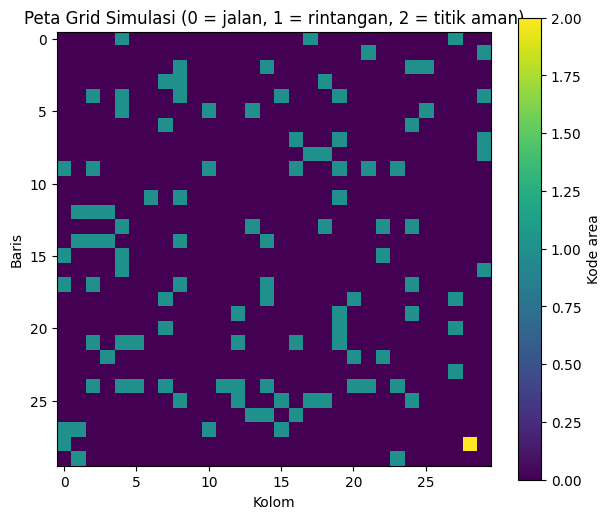

In [2]:
GRID_SIZE = 30
SAFE_ZONE = (GRID_SIZE - 2, GRID_SIZE - 2)

def create_grid(seed=42, obstacle_ratio=0.12):
    rng = np.random.default_rng(seed)
    grid = np.zeros((GRID_SIZE, GRID_SIZE), dtype=int)

    # Membuat rintangan secara acak
    obstacles = rng.random((GRID_SIZE, GRID_SIZE)) < obstacle_ratio
    grid[obstacles] = 1

    # Pastikan area awal dan titik aman tidak terhalang
    grid[1, 1] = 0
    grid[SAFE_ZONE] = 2

    # Membuka koridor sederhana menuju titik aman agar simulasi punya jalur
    grid[1:SAFE_ZONE[0] + 1, SAFE_ZONE[1]] = 0
    grid[SAFE_ZONE[0], 1:SAFE_ZONE[1] + 1] = 0
    grid[SAFE_ZONE] = 2
    return grid

grid = create_grid()
plt.figure(figsize=(7, 6))
plt.imshow(grid, origin="upper")
plt.title("Peta Grid Simulasi (0 = jalan, 1 = rintangan, 2 = titik aman)")
plt.xlabel("Kolom")
plt.ylabel("Baris")
plt.colorbar(label="Kode area")
plt.show()

In [3]:
def run_simulation(args):
    # Fungsi dibuat di level utama agar dapat dipakai ProcessPoolExecutor di Colab
    seed, population, max_steps = args
    rng = random.Random(seed)
    local_grid = create_grid(seed=seed)
    safe_r, safe_c = SAFE_ZONE

    # Pilih posisi awal yang tidak berupa rintangan dan bukan titik aman
    starts = []
    while len(starts) < population:
        r = rng.randrange(1, GRID_SIZE - 1)
        c = rng.randrange(1, GRID_SIZE - 1)
        if local_grid[r, c] != 1 and (r, c) != SAFE_ZONE:
            starts.append((r, c))

    evacuated = 0
    total_steps = 0
    final_positions = []

    for start in starts:
        r, c = start
        for step in range(max_steps):
            if (r, c) == SAFE_ZONE:
                evacuated += 1
                total_steps += step
                break

            candidates = []
            for nr, nc in [(r-1,c), (r+1,c), (r,c-1), (r,c+1)]:
                if 0 <= nr < GRID_SIZE and 0 <= nc < GRID_SIZE and local_grid[nr, nc] != 1:
                    # Prioritaskan gerakan yang mengurangi jarak Manhattan ke titik aman
                    distance = abs(safe_r - nr) + abs(safe_c - nc)
                    candidates.append((distance, nr, nc))

            if not candidates:
                break

            best_distance = min(item[0] for item in candidates)
            best_moves = [item for item in candidates if item[0] == best_distance]
            _, r, c = rng.choice(best_moves)

        final_positions.append((r, c))

    return {
        "seed": seed,
        "population": population,
        "evacuated": evacuated,
        "success_rate": evacuated / population,
        "average_steps": total_steps / evacuated if evacuated else None,
    }

demo_result = run_simulation((7, 100, 100))
demo_result

{'seed': 7,
 'population': 100,
 'evacuated': 100,
 'success_rate': 1.0,
 'average_steps': 28.39}

In [4]:
NUM_SCENARIOS = 12
POPULATION = 150
MAX_STEPS = 100

tasks = [(seed, POPULATION, MAX_STEPS) for seed in range(100, 100 + NUM_SCENARIOS)]

# Eksekusi serial
start_time = time.perf_counter()
serial_results = [run_simulation(task) for task in tasks]
serial_time = time.perf_counter() - start_time

print(f"Waktu serial: {serial_time:.3f} detik")
print(f"Rata-rata keberhasilan evakuasi: {np.mean([r['success_rate'] for r in serial_results]) * 100:.1f}%")

Waktu serial: 0.183 detik
Rata-rata keberhasilan evakuasi: 98.8%


In [5]:
# Eksekusi paralel
# Di Google Colab, ProcessPoolExecutor dapat bergantung pada kondisi runtime.
# Jika terjadi error, jalankan kembali sel ini atau gunakan hasil serial sebagai demonstrasi.
start_time = time.perf_counter()

try:
    with ProcessPoolExecutor(max_workers=min(4, os.cpu_count() or 2)) as executor:
        parallel_results = list(executor.map(run_simulation, tasks))
    parallel_time = time.perf_counter() - start_time
    parallel_ok = True
    print(f"Waktu paralel: {parallel_time:.3f} detik")
except Exception as error:
    parallel_results = []
    parallel_time = None
    parallel_ok = False
    print("Eksekusi paralel tidak berhasil pada runtime ini.")
    print("Detail error:", repr(error))
    print("Tetap gunakan hasil serial untuk memahami alur simulasi.")

Waktu paralel: 0.210 detik


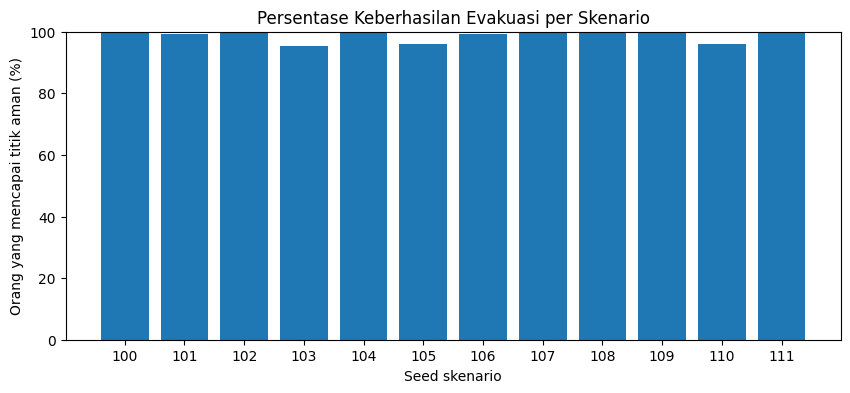

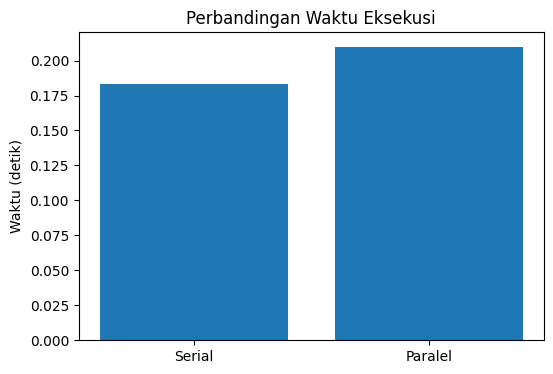

Percepatan (speedup): 0.87x


In [6]:
scenario_ids = [r["seed"] for r in serial_results]
success_rates = [r["success_rate"] * 100 for r in serial_results]

plt.figure(figsize=(10, 4))
plt.bar([str(s) for s in scenario_ids], success_rates)
plt.title("Persentase Keberhasilan Evakuasi per Skenario")
plt.xlabel("Seed skenario")
plt.ylabel("Orang yang mencapai titik aman (%)")
plt.ylim(0, 100)
plt.show()

if parallel_ok:
    plt.figure(figsize=(6, 4))
    plt.bar(["Serial", "Paralel"], [serial_time, parallel_time])
    plt.title("Perbandingan Waktu Eksekusi")
    plt.ylabel("Waktu (detik)")
    plt.show()

    if parallel_time > 0:
        print(f"Percepatan (speedup): {serial_time / parallel_time:.2f}x")
else:
    print("Grafik perbandingan waktu dilewati karena eksekusi paralel tidak berhasil.")

In [7]:
mean_success = np.mean([r["success_rate"] for r in serial_results]) * 100
print("Jumlah skenario:", len(serial_results))
print(f"Rata-rata keberhasilan evakuasi: {mean_success:.2f}%")
print(f"Waktu eksekusi serial: {serial_time:.3f} detik")

if parallel_ok:
    print(f"Waktu eksekusi paralel: {parallel_time:.3f} detik")
    if parallel_time < serial_time:
        print("Pada percobaan ini, eksekusi paralel lebih cepat.")
    else:
        print("Pada percobaan ini, eksekusi paralel tidak lebih cepat.")
else:
    print("Waktu paralel tidak tersedia pada runtime ini.")

Jumlah skenario: 12
Rata-rata keberhasilan evakuasi: 98.83%
Waktu eksekusi serial: 0.183 detik
Waktu eksekusi paralel: 0.210 detik
Pada percobaan ini, eksekusi paralel tidak lebih cepat.
